# Measuring and correcting aberrations with the SLM itself: Zernike modes and sensorless recovery

**Question:** How are the aberrations of the optical system measured and corrected with the SLM itself, and how closely does a search that sees only the camera recover the wavefront?

- Level: 2, the method in practice.
- Prerequisites: `01-fourier-optics/01-where-the-light-goes` for the focal field, and `06-device-and-aberrations/01-what-the-device-costs` for the idea of a displayed pattern that differs from the computed one.
- Reading time: about 25 minutes. The notebook runs in about 40 seconds.

## Objectives

The lenses between the SLM and the atoms or beads are not perfect, and their errors add a smooth phase to the wavefront that the hologram was computed for. The SLM sits in the pupil, so it can subtract that phase again, if the phase is known. This notebook shows how it is described, what it costs, and how it is found without a wavefront sensor. By the end you can:

- describe a wavefront with Zernike modes in Noll order, and check that the modes are orthonormal over the pupil;
- turn a list of coefficients into an rms error in waves and a first estimate of the light that is lost;
- measure, on this array, how the trap light falls as one coefficient is left wrong, and compare it with the Maréchal curve;
- run the sensorless modal search of M14 with an ideal camera and with a noisy one, and read how closely it recovers the coefficients;
- say what the correction assumes about the aberration.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.camera import EmulatedCamera
from pipeline.model.holo.core.geometry import slm_grid
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.core.zernike import noll_to_nm, rms_waves, strehl, zernike
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.control import m14_zernike

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C09 of `data/examples/cases.json`: 16 traps on a 256 x 256 pixel SLM, and a system aberration given as Noll coefficients in waves.

- Owner: this repository; the case is synthetic, and its aberration is a stated model, not a measurement of an instrument.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C09.

In [2]:
# case C09: 16 traps and a system aberration given as Noll coefficients in waves
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C09"]
setup = build.setup_of(rec)
target = build.target_of(rec)
coeffs = build.aberration_coeffs(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")
print("aberration (Noll j: waves):", rec["aberration"]["noll"])

C09_aberrated | 16 traps | SLM 256 x 256 pixels
aberration (Noll j: waves): {'4': 0.08, '5': 0.07, '6': 0.05, '7': 0.06, '8': -0.05, '11': 0.04}


## Method

### Step 1: the Zernike modes

A smooth wavefront over a round pupil is written as a sum of modes, $W(\rho, \theta) = \sum_j c_j Z_j(\rho, \theta)$, with $c_j$ in waves. The modes $Z_n^m = N_n^m R_n^{|m|}(\rho) \cos(m\theta)$ or $\sin(|m|\theta)$ are indexed by the single number $j$ of Noll (1976), which orders them by radial degree $n$ and then by angular order $m$: $j = 4$ is defocus, 5 and 6 are the two astigmatisms, 7 and 8 coma, 9 and 10 trefoil, 11 primary spherical. The pipeline normalises them to unit rms over the disc, so they are orthonormal, and the rms wavefront error is simply the root of the sum of the squared coefficients. The cell evaluates modes 4 to 11 on the pupil of the SLM (a disc inscribed in the pixel grid) and computes their mean products, which should be the identity matrix.

In [3]:
# Zernike modes 4 to 11 on the SLM pupil, and their mean products over the disc
x, y = slm_grid(setup)
radius = setup.n_pix * setup.pitch_m / 2
rho, theta = np.hypot(x, y) / radius, np.arctan2(y, x)
js = list(range(4, 12))
modes = np.array([zernike(j, rho, theta) for j in js])
inside = rho <= 1
gram = modes[:, inside] @ modes[:, inside].T / inside.sum()
for k, j in enumerate(js):
    print(f"j = {j:2d}: (n, m) = {noll_to_nm(j)}  mean square over the disc {gram[k, k]:.3f}")
print(f"largest product between two different modes: {np.abs(gram - np.diag(np.diag(gram))).max():.4f}")

j =  4: (n, m) = (2, 0)  mean square over the disc 1.000
j =  5: (n, m) = (2, -2)  mean square over the disc 0.999
j =  6: (n, m) = (2, 2)  mean square over the disc 1.001
j =  7: (n, m) = (3, -1)  mean square over the disc 1.000
j =  8: (n, m) = (3, 1)  mean square over the disc 1.000
j =  9: (n, m) = (3, -3)  mean square over the disc 1.000
j = 10: (n, m) = (3, 3)  mean square over the disc 1.000
j = 11: (n, m) = (4, 0)  mean square over the disc 1.000
largest product between two different modes: 0.0013


The eight modes are drawn as maps over the pupil, in the same colour scale.

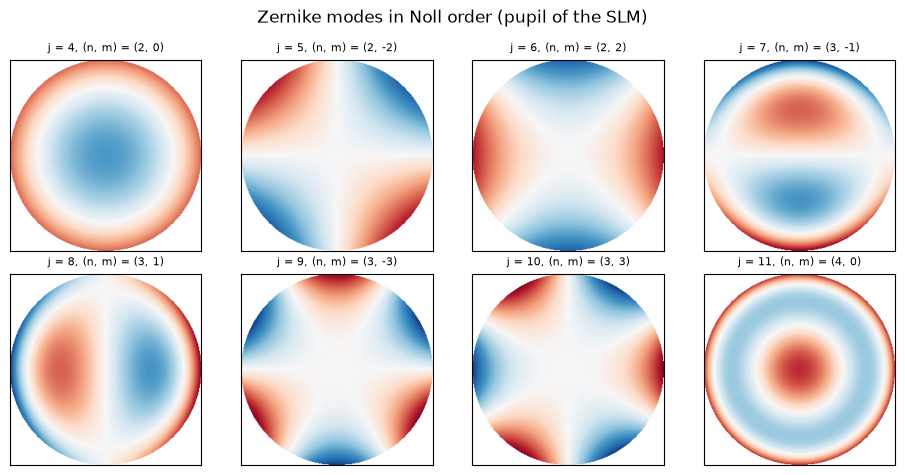

In [4]:
# the eight modes as maps on the pupil, in waves per unit coefficient
fig, axes = plt.subplots(2, 4, figsize=(9.4, 4.8))
for ax, j, mode in zip(axes.ravel(), js, modes):
    shown = np.where(inside, mode, np.nan)
    ax.imshow(shown, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(f"j = {j}, (n, m) = {noll_to_nm(j)}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Zernike modes in Noll order (pupil of the SLM)")
plt.tight_layout()
plt.show()

The table shows what orthonormal means in practice: each mode has a mean square of 1.000 over the disc (0.999 to 1.001, the difference being the discretisation of a disc on 256 x 256 pixels), and the largest product between two different modes is 0.0013. The maps show what each coefficient does to a wavefront. Defocus is a bowl, the astigmatisms are saddles at 45 degrees from each other, coma is a tilt that reverses at the centre, trefoil has three lobes, and spherical aberration is a bowl with a ring. The orthogonality is what makes the next step possible, because the coefficients can be changed one at a time without disturbing the others, and it makes the rms error a sum of squares. The figure does not show the modes at high order, which are not in the first 21 the pipeline carries, or the tip, tilt and piston, which move or do not change the traps.

### Step 2: the aberration of the case, and what it costs

Case C09 gives six coefficients, from 0.04 to 0.08 waves in size. Their root sum of squares is the rms wavefront error. The Maréchal approximation (Noll 1976 gives the rms; the exponential form is the standard small-aberration estimate, and the pipeline's module states it as unverified against the paper) turns the rms into a Strehl ratio, the fraction of peak intensity left, $S \approx \exp[-(2\pi\sigma_W)^2]$. It is meant for $\sigma_W$ below about $1/14$ wave. The cell prints both numbers for the case.

In [5]:
# the aberration of C09: rms over the pupil, and the Marechal estimate of the Strehl ratio
sigma_w = rms_waves(coeffs)
print(f"rms wavefront error: {sigma_w:.4f} waves")
print(f"Marechal estimate of the Strehl ratio: {strehl(coeffs):.4f}")
print(f"largest coefficient: {max(coeffs, key=abs):+.2f} waves")
print(f"piston excluded; modes in use: {[j for j, c in enumerate(coeffs, start=1) if c != 0]}")

rms wavefront error: 0.1466 waves
Marechal estimate of the Strehl ratio: 0.4279
largest coefficient: +0.08 waves
piston excluded; modes in use: [4, 5, 6, 7, 8, 11]


The case's wavefront has an rms of 0.1466 waves, about twice the validity range of the estimate, and the Maréchal Strehl is 0.4279. To see what the aberration does to light in the traps, compute a weighted-GS hologram for the ideal system (M06, 30 iterations), and ask M14 in its `correct` mode to display it through the aberrated system twice: once with nothing subtracted, and once with the exact coefficients subtracted from the displayed phase, $\phi_\text{shown} = \phi_\text{base} - 2\pi \sum_j \hat c_j Z_j$.

In [6]:
# the hologram computed for the ideal system, and the same hologram through the aberrated one
base = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1), form="point")
exact = m14_zernike.run(setup, target, budget=Budget(1), rng=Rng(1), init=base.phi, mode="correct",
                        injected=coeffs, known=coeffs)
e_ideal, e_aberrated = exact.meta["base_efficiency"], exact.meta["uncorrected_efficiency"]
print(f"efficiency without aberration: {e_ideal:.4f}")
print(f"efficiency with the aberration, uncorrected: {e_aberrated:.4f}")
print(f"efficiency with the exact correction: {exact.history[-1]['efficiency']:.4f}")
print(f"measured ratio {e_aberrated / e_ideal:.4f} | Marechal estimate {strehl(coeffs):.4f}")

efficiency without aberration: 0.7938
efficiency with the aberration, uncorrected: 0.4462
efficiency with the exact correction: 0.7938
measured ratio 0.5621 | Marechal estimate 0.4279


The aberration takes the efficiency from 0.7938 to 0.4462, a ratio of 0.5621, and the exact correction brings it back to 0.7938, because in the model the two phases cancel. The Maréchal estimate of 0.4279 is the right order but clearly pessimistic for this array, since it describes the peak of one spot at a larger rms than it is meant for, and the efficiency here is a sum over 16 traps.

### Step 3: the merit that a sensorless search climbs

A correction is only useful if the coefficients are known, and the point of a sensorless method is to find them from the light itself. The camera sees the sum of the trap intensities, $M(\hat c) = \sum_m I_m$. If $M$ falls off as a Gaussian of the residual, $M \propto \exp[-(2\pi r)^2]$ for a residual of $r$ waves in one mode, then $\ln M$ is a parabola in each coefficient, and three measurements locate its vertex. The cell tests that assumption on one mode: it corrects all the modes exactly except defocus (j = 4), which it leaves wrong by $r$, and records the efficiency relative to the ideal system.

In [7]:
# one mode left wrong: defocus (j = 4) corrected with an error r, all others exact; efficiency against r
residual = np.linspace(-0.15, 0.15, 13)
scan = []
for r in residual:
    known = list(coeffs)
    known[3] -= r
    res = m14_zernike.run(setup, target, budget=Budget(1), rng=Rng(1), init=base.phi, mode="correct",
                          injected=coeffs, known=known)
    scan.append(res.history[-1]["efficiency"] / e_ideal)
scan = np.array(scan)
for r, ratio in list(zip(residual, scan))[::3]:
    marechal = np.exp(-(2 * np.pi * r) ** 2)
    print(f"r = {r:+.3f} waves: efficiency ratio {ratio:.4f} | exp(-(2 pi r)^2) = {marechal:.4f}")

r = -0.150 waves: efficiency ratio 0.4457 | exp(-(2 pi r)^2) = 0.4114
r = -0.075 waves: efficiency ratio 0.8245 | exp(-(2 pi r)^2) = 0.8009
r = +0.000 waves: efficiency ratio 1.0000 | exp(-(2 pi r)^2) = 1.0000
r = +0.075 waves: efficiency ratio 0.8239 | exp(-(2 pi r)^2) = 0.8009
r = +0.150 waves: efficiency ratio 0.4451 | exp(-(2 pi r)^2) = 0.4114


The figure plots the measured ratio against the Gaussian curve.

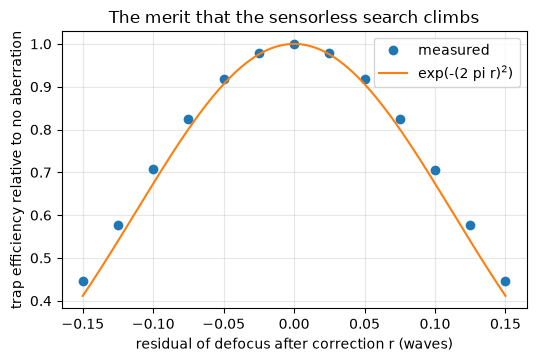

In [8]:
# the efficiency ratio against the residual of one mode, with the Marechal curve
fine = np.linspace(-0.15, 0.15, 200)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.plot(residual, scan, "o", label="measured")
ax.plot(fine, np.exp(-(2 * np.pi * fine) ** 2), "-", label="exp(-(2 pi r)$^2$)")
ax.set_xlabel("residual of defocus after correction r (waves)")
ax.set_ylabel("trap efficiency relative to no aberration")
ax.set_title("The merit that the sensorless search climbs")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

The measured points are symmetric about zero, as a Gaussian would be (0.8245 at -0.075 waves and 0.8239 at +0.075; 0.4457 and 0.4451 at the extremes of 0.15), and they follow the curve $\exp[-(2\pi r)^2]$ within a few percent: 0.8245 against 0.8009 at 0.075 waves and 0.4457 against 0.4114 at 0.15. The measured curve is slightly wider than the Maréchal one, which is a gain for the search, since the merit is flatter near the optimum than the estimate says. The symmetry means that one mode has one maximum, so a three-point parabola is the right local model, and that is all the search needs. The figure tests one mode, defocus, with the other seven exact; it does not test how the modes interact when all are wrong, which is why the search repeats its sweeps.

### Step 4: the sensorless search

M14 in `recover` mode visits modes 4 to 11. For each one it measures the merit at $\hat c_j - \delta$, $\hat c_j$ and $\hat c_j + \delta$ with $\delta = 0.06$ waves, fits a parabola to the logarithm and moves to its vertex, with the step limited to $2\delta$. One sweep over the eight modes costs 25 camera frames. The modes are not exactly independent under a Gaussian beam and off-axis traps, so the sweep is repeated until the largest update is below $10^{-4}$ waves, or until the budget of sweeps is spent. The camera is the emulated one of the pipeline. The first run uses its default, ideal gains and no noise; the second adds Gaussian noise of rms 0.003 in the units of the trap intensity, about 6 percent of a trap's mean intensity here.

In [9]:
# sensorless recovery of modes 4 to 11 with an ideal camera, and with a camera that adds noise (rms 0.003)
ideal_run = m14_zernike.run(setup, target, budget=Budget(6), rng=Rng(1), init=base.phi, mode="recover", injected=coeffs)
noisy_camera = EmulatedCamera(seed=3, gain_rms=0.0, noise_rms=0.003, rolloff=False)
noisy_run = m14_zernike.run(setup, target, budget=Budget(6), rng=Rng(1), init=base.phi, mode="recover", injected=coeffs,
                            camera=noisy_camera)
for name, run in (("ideal camera", ideal_run), ("noisy camera", noisy_run)):
    for h in run.history:
        print(f"{name:18s} sweep {h['iteration']}: efficiency {h['efficiency']:.4f}  "
              f"coefficient rms error {h['coef_rms_error']:.5f}")

ideal camera       sweep 1: efficiency 0.7880  coefficient rms error 0.01562
ideal camera       sweep 2: efficiency 0.7938  coefficient rms error 0.00082
ideal camera       sweep 3: efficiency 0.7938  coefficient rms error 0.00032
ideal camera       sweep 4: efficiency 0.7938  coefficient rms error 0.00033
noisy camera       sweep 1: efficiency 0.7426  coefficient rms error 0.04774
noisy camera       sweep 2: efficiency 0.7899  coefficient rms error 0.01315
noisy camera       sweep 3: efficiency 0.7924  coefficient rms error 0.00815
noisy camera       sweep 4: efficiency 0.7914  coefficient rms error 0.01010
noisy camera       sweep 5: efficiency 0.7911  coefficient rms error 0.01158
noisy camera       sweep 6: efficiency 0.7907  coefficient rms error 0.01193


The left panel shows the rms error of the recovered coefficients after each sweep, and the right panel the injected and recovered coefficients of the ideal-camera run.

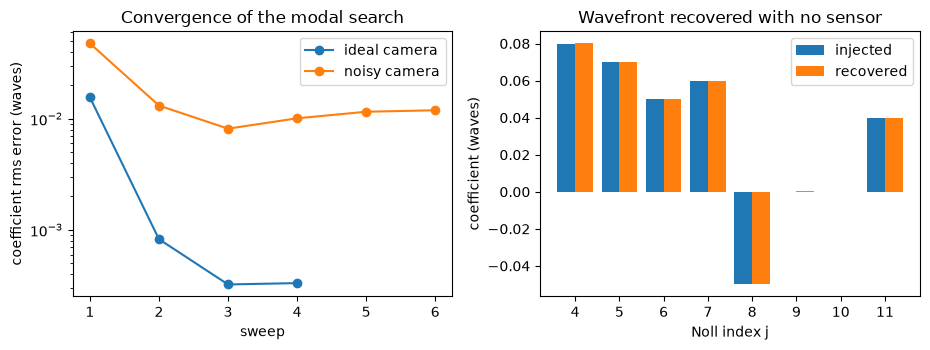

In [10]:
# left: coefficient error per sweep; right: injected and recovered coefficients (ideal camera)
fig, (a, b) = plt.subplots(1, 2, figsize=(9.4, 3.6))
for name, run in (("ideal camera", ideal_run), ("noisy camera", noisy_run)):
    a.semilogy([h["iteration"] for h in run.history], [h["coef_rms_error"] for h in run.history], "o-", label=name)
a.set_xlabel("sweep")
a.set_ylabel("coefficient rms error (waves)")
a.set_title("Convergence of the modal search")
a.legend()
slots = np.arange(len(js))
b.bar(slots - 0.2, [coeffs[j - 1] if j <= len(coeffs) else 0.0 for j in js], 0.4, label="injected")
b.bar(slots + 0.2, [ideal_run.meta["coefficients"][j - 1] for j in js], 0.4, label="recovered")
b.set_xticks(slots)
b.set_xticklabels([str(j) for j in js])
b.set_xlabel("Noll index j")
b.set_ylabel("coefficient (waves)")
b.set_title("Wavefront recovered with no sensor")
b.legend()
plt.tight_layout()
plt.show()

With an ideal camera the search converges in four sweeps: the rms error of the coefficients falls from 0.01562 waves after the first sweep to 0.00082 after the second and 0.00032 after the third, where it stops improving, and the efficiency reaches 0.7938, that of the system without aberration, from sweep 2. In the right panel the bars cannot be told apart; the two modes that were not injected, 9 and 10, are recovered as zero. With the noisy camera the first sweep leaves an error of 0.04774 and an efficiency of 0.7426, the second brings the error to 0.01315, and then the error stops falling, between 0.00815 and 0.01193 waves, because a parabola fitted to three noisy values has a vertex that moves with the noise. The efficiency still reaches 0.7907 to 0.7924, within 0.4 percent of the ideal 0.7938, since a residual of 0.01 waves in each mode costs little light. The figure shows the search with one injected aberration and one noise level, and a camera with a per-trap gain error would add a bias that this run does not have. It also assumes the aberration is the same at every trap, which is the premise of a global correction.

## Results

**Answer:** The aberrations are described by Zernike coefficients, found by a search that uses only the summed trap light, and corrected by subtracting the recovered wavefront from the displayed phase. The modes are orthonormal over the pupil (mean square 1.000, largest cross product 0.0013), so the rms error of the case, 0.1466 waves, is a sum of squares, and it cuts the efficiency of the 16 traps from 0.7938 to 0.4462 (Maréchal's estimate of the light, 0.4279, is the right order but pessimistic). The merit is a clean Gaussian-like function of each coefficient (a ratio of 0.8245 at a residual of 0.075 waves against the 0.8009 of the exponential), so three camera frames per mode locate its optimum: with an ideal camera four sweeps, 100 frames, recover the eight coefficients to a rms error of 0.00033 waves and return the efficiency to 0.7938. With camera noise of 0.003 the error stops near 0.01193 waves and the efficiency is 0.7907.

What the notebook does not show is a correction that varies across the field, a camera with gain errors per trap, or modes above j = 11.

## Summary

- A wavefront is a sum of Zernike modes; in the orthonormal basis of the pipeline its rms error is the root of the sum of squared coefficients.
- The aberration of case C09 is 0.1466 waves rms and cuts the trap efficiency by 44 percent; the Maréchal estimate of the loss is pessimistic at this size.
- The summed trap intensity is close to a Gaussian in each coefficient, so a three-point parabola in $\ln M$ finds the optimum of a mode.
- The sensorless search of M14 recovers the eight coefficients to 0.00033 waves in four sweeps with an ideal camera, and to about 0.01 waves with a noisy one.
- The correction is global: it assumes one aberration for all traps and tests nothing about field-dependent errors.

## References

- Noll (1976). Zernike polynomials and atmospheric turbulence. Journal of the Optical Society of America 66, 207. https://doi.org/10.1364/JOSA.66.000207
- Nogrette et al. (2014). Single-atom trapping in holographic 2D arrays of microtraps with arbitrary geometries. Physical Review X 4, 021034. https://arxiv.org/abs/1402.5329